# Employee Attrition: Survival-First Modelling

Exit interviews explain attrition after the fact. This model looks forward and answers two questions:
1. **Cox proportional hazards** (primary): which factors *multiply* the risk of leaving, and by how much?
2. **XGBoost triage** (secondary): who should HR business partners talk to **this month**?

*Synthetic HR data. The real pipeline ran on a bank's HR system.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
import subprocess, sys, json, pandas as pd
from IPython.display import Image, display
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True, capture_output=True)
from src.features import connect, build_model_base
con = connect()
con.execute("SELECT COALESCE(exit_reason,'(active)') AS exit_reason, COUNT(*) AS records FROM employee_details GROUP BY 1 ORDER BY 2 DESC").df()

,exit_reason,records
0,(active),3438
1,RESIGNATION,2005
2,TERMINATION,951
3,WITHDRAWAL_OF_SERVICE,508
4,RETIREMENT,357
5,DUPLICATE_RECORD,110
6,DEATH,46


## 1. Defining the target is half the work
The HR system mixes very different kinds of exit:

| Exit reason | Treatment | Why |
|---|---|---|
| Resignation, withdrawal of service, termination | **Event** | The attrition we want to predict and prevent |
| Retirement | **Censored**, handled by rule | Known in advance from statutory age; nothing to predict |
| Death | Excluded | Not attrition |
| Duplicate record | Excluded | Data-quality artefact |

This logic lives in `sql/views/v1_employee_clean.sql`.

## 2. Five SQL views
`v1` clean base → `v2` survival spells from a landmark date → `v3` compensation (pay vs grade median, months since raise or promotion) → `v4` mobility (manager changes, transfers) → `v5` performance (latest rating and its change).

In [2]:
tr = build_model_base(con, "2024-06-30")
tr.describe().T[["mean","50%","min","max"]].round(2)

,mean,50%,min,max
duration_months,20.861152,23.981603,0.032852,23.981603
event,0.196837,0.0,0.0,1.0
exit_within_horizon,0.075864,0.0,0.0,1.0
tenure_months,72.635911,60.0,0.0,336.0
age_years,44.148579,43.997262,22.409309,59.997262
grade,2.81488,3.0,1.0,6.0
pay_vs_grade_median,1.026743,1.0,0.589361,1.965027
months_since_raise,11.108377,5.0,0.0,196.0
months_since_promotion,55.15495,39.0,0.0,283.0
pay_growth_24m,0.090358,0.069605,0.0,0.769133


## 3. Cox PH: what multiplies the hazard

,covariate,hazard_ratio,ci_low,ci_high,p
0,low_rating,1.293,1.089,1.537,0.003
1,recent_mgr_change,1.019,0.837,1.242,0.850
2,months_since_raise,1.018,1.010,1.026,0.000
3,age_years,1.000,0.985,1.016,0.959
4,tenure_years,0.987,0.967,1.009,0.246
5,grade,0.973,0.903,1.048,0.469
6,underpaid_high_performer,0.940,0.767,1.151,0.550
7,pay_vs_grade_median,0.668,0.629,0.711,0.000


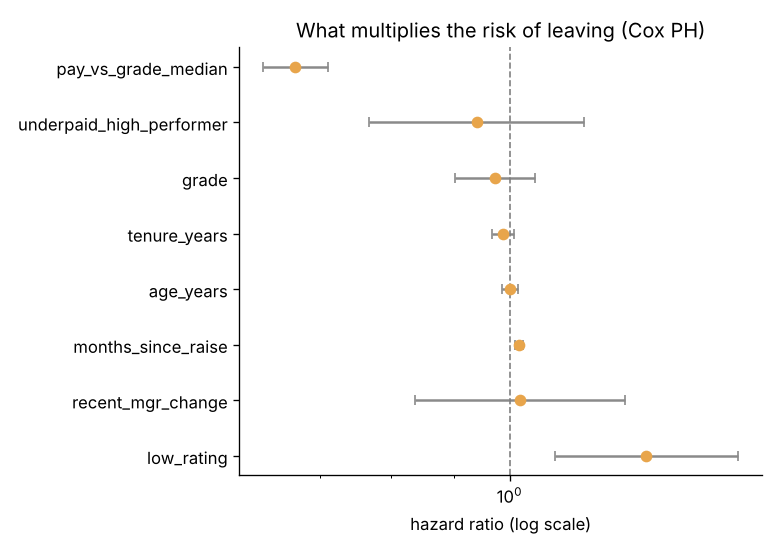

Concordance  train: 0.6878  OOT: 0.712


In [3]:
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
m = json.load(open("reports/metrics.json"))
display(pd.read_csv("reports/cox_hazard_ratios.csv"))
display(Image("reports/figures/cox_hazard_ratios.png", width=560))
print("Concordance  train:", m["cox_concordance_train"], " OOT:", m["cox_concordance_oot"])

**Reading the hazard ratios**
* **Pay vs grade median** is the strongest lever. Each extra 10% of the grade median cuts the hazard by about a third (HR ≈ 0.67).
* **Months since last raise** adds about 2% hazard per month. After 18 months without a raise, risk is roughly 1.4× higher.
* **A low rating** raises the hazard by about 30%, through managed exits as well as resignations.
* Once pay is in the model, "underpaid high performer" adds nothing extra. The pay gap itself is what drives it.

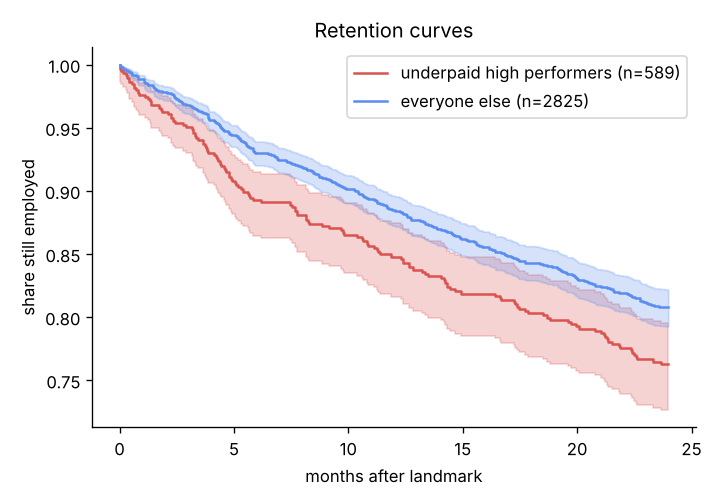

In [4]:
display(Image('reports/figures/km_underpaid_high_performers.png', width=520))

## 4. Monthly triage list
The Cox model sets policy. HR partners also need a list of names. XGBoost predicts exit within 6 months, trained on the 2024 landmark and tested on the 2025 one.

OOT AUC 0.732 | precision of top-50 list 28% vs base rate 5.5%


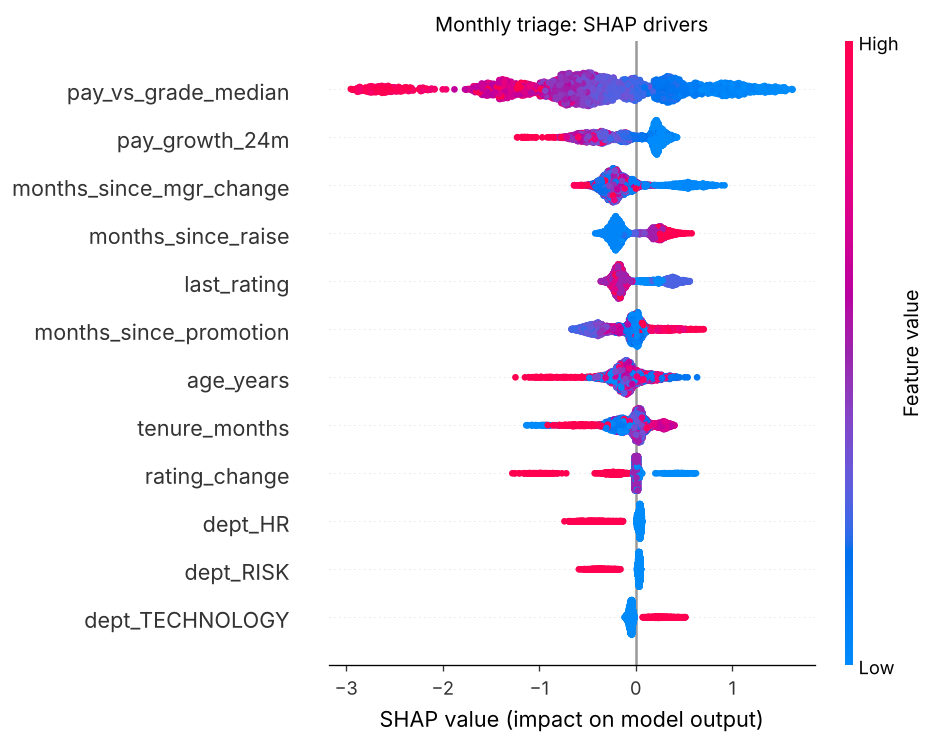

,emp_id,department,grade,risk_6m,top_reasons
0,E56412,CORPORATE_BANKING,5,0.9089,"pay_vs_grade_median, months_since_mgr_change, ..."
1,E56703,HR,1,0.8976,"pay_vs_grade_median, months_since_mgr_change, ..."
2,E56628,TREASURY,5,0.8905,"pay_vs_grade_median, age_years, pay_growth_24m"
3,E56798,TECHNOLOGY,3,0.8880,"pay_vs_grade_median, months_since_mgr_change, ..."
4,E56455,RETAIL_BRANCHES,6,0.8783,"pay_vs_grade_median, months_since_mgr_change, ..."
5,E56456,TREASURY,5,0.8767,"pay_vs_grade_median, last_rating, pay_growth_24m"
6,E56438,TREASURY,3,0.8765,"pay_vs_grade_median, months_since_mgr_change, ..."
7,E56622,CORPORATE_BANKING,2,0.8742,"pay_vs_grade_median, months_since_mgr_change, ..."
8,E56699,OPERATIONS,2,0.8736,"pay_vs_grade_median, months_since_mgr_change, ..."
9,E55765,TECHNOLOGY,2,0.8710,"pay_vs_grade_median, last_rating, pay_growth_24m"


In [5]:
print(f"OOT AUC {m['triage_auc_oot']:.3f} | precision of top-50 list {m['triage_precision_at_50']:.0%} vs base rate {m['triage_base_rate_6m']:.1%}")
display(Image("reports/figures/shap_triage.png", width=600))
pd.read_csv("reports/triage_list_oot.csv").head(10)